# ЛР2. Разведочный анализ и подготовка данных

**Датасет:** `RealEstate.zip` → `train.csv`. Это 10 000 квартир с характеристиками и ценой (`Price`).

**Цель работы:** освоить инструменты сбора и подготовки данных:
1. импортировать датасет;
2. найти пропуски и аномальные значения (статистикой и графиками), заполнить пропуски, устранить выбросы и проверить результат графиками;
3. сгенерировать новые признаки (не меньше двух) и закодировать категориальные признаки (OHE, бинаризация);
4. стандартизировать и нормализовать данные.

**Описание столбцов**

| Столбец | Смысл |
|---|---|
| `Id` | номер квартиры |
| `DistrictId` | номер района |
| `Rooms` | число комнат |
| `Square`, `LifeSquare`, `KitchenSquare` | общая, жилая и кухонная площадь, м² |
| `Floor`, `HouseFloor` | этаж квартиры и этажность дома |
| `HouseYear` | год постройки дома |
| `Ecology_1..3` | экологические показатели района (`_2`, `_3` категориальные: A/B) |
| `Social_1..3` | социальные показатели района |
| `Healthcare_1`, `Helthcare_2` | показатели медицины в районе |
| `Shops_1`, `Shops_2` | магазины рядом (`Shops_2` категориальный: A/B) |
| `Price` | цена квартиры (**целевая переменная**) |

## 0. Библиотеки

- **pandas**: таблица `DataFrame`, загрузка, фильтры, группировки;
- **numpy**: математика над массивами;
- **matplotlib / seaborn**: графики;
- **scikit-learn**: готовые инструменты для кодирования и масштабирования признаков.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder, Binarizer

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

MAIN = "#3b6fb6"   # один цвет для всех «одиночных» графиков

## 1. Импорт датасета

`pd.read_csv` умеет читать CSV прямо из zip-архива, если в архиве один файл, поэтому распаковывать его не нужно.

In [2]:
df = pd.read_csv("../RealEstate.zip")
raw = df.copy()          # исходная копия: пригодится для графиков «до / после»
print("Размер:", df.shape)
df.head()

Размер: (10000, 20)


,Id,DistrictId,Rooms,Square,LifeSquare,KitchenSquare,Floor,HouseFloor,HouseYear,Ecology_1,Ecology_2,Ecology_3,Social_1,Social_2,Social_3,Healthcare_1,Helthcare_2,Shops_1,Shops_2,Price
0,11809,27,3.0,115.027311,NaN,10.0,4,10.0,2014,0.075424,B,B,11,3097,0,NaN,0,0,B,305018.871089
1,3013,22,1.0,39.832524,23.169223,8.0,7,8.0,1966,0.118537,B,B,30,6207,1,1183.0,1,0,B,177734.553407
2,8215,1,3.0,78.342215,47.671972,10.0,2,17.0,1988,0.025609,B,B,33,5261,0,240.0,3,1,B,282078.720850
3,2352,1,1.0,40.409907,NaN,1.0,10,22.0,1977,0.007122,B,B,1,264,0,NaN,0,1,B,168106.007630
4,13866,94,2.0,64.285067,38.562517,9.0,16,16.0,1972,0.282798,B,B,33,8667,2,NaN,0,6,B,343995.102962


`df.info()` показывает тип каждого столбца и число **непустых** значений.
Если непустых меньше 10 000, в столбце есть пропуски.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             10000 non-null  int64  
 1   DistrictId     10000 non-null  int64  
 2   Rooms          10000 non-null  float64
 3   Square         10000 non-null  float64
 4   LifeSquare     7887 non-null   float64
 5   KitchenSquare  10000 non-null  float64
 6   Floor          10000 non-null  int64  
 7   HouseFloor     10000 non-null  float64
 8   HouseYear      10000 non-null  int64  
 9   Ecology_1      10000 non-null  float64
 10  Ecology_2      10000 non-null  str    
 11  Ecology_3      10000 non-null  str    
 12  Social_1       10000 non-null  int64  
 13  Social_2       10000 non-null  int64  
 14  Social_3       10000 non-null  int64  
 15  Healthcare_1   5202 non-null   float64
 16  Helthcare_2    10000 non-null  int64  
 17  Shops_1        10000 non-null  int64  
 18  Shops_2        100

`describe()` выводит основные статистики по числовым столбцам: среднее, стандартное отклонение, минимум, квартили и максимум.
**Это первый инструмент поиска аномалий:** смотрим на `min` и `max` и спрашиваем себя, бывает ли такое в жизни.

In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Id,10000.0,8383.41,4859.02,0.00,4169.50,8394.50,12592.50,16798.00
DistrictId,10000.0,50.40,43.59,0.00,20.00,36.00,75.00,209.00
Rooms,10000.0,1.89,0.84,0.00,1.00,2.00,2.00,19.00
Square,10000.0,56.32,21.06,1.14,41.77,52.51,65.90,641.07
LifeSquare,7887.0,37.20,86.24,0.37,22.77,32.78,45.13,7480.59
KitchenSquare,10000.0,6.27,28.56,0.00,1.00,6.00,9.00,2014.00
Floor,10000.0,8.53,5.24,1.00,4.00,7.00,12.00,42.00
HouseFloor,10000.0,12.61,6.78,0.00,9.00,13.00,17.00,117.00
HouseYear,10000.0,3990.17,200500.26,1910.00,1974.00,1977.00,2001.00,20052011.00
Ecology_1,10000.0,0.12,0.12,0.00,0.02,0.08,0.20,0.52


**Что видно сразу:**
- `HouseYear` max = **20 052 011**: опечатка, похоже на «2005–2011»;
- `Rooms` min = 0 и max = 19: квартир без комнат не бывает, 19 комнат при такой площади тоже;
- `Square` min ≈ 1 м², max ≈ 641 м²;
- `LifeSquare` max ≈ 7 480 м², `KitchenSquare` max = 2 014 м² (похоже на год, записанный не в тот столбец);
- `HouseFloor` min = 0 (дом без этажей) и max = 117;
- у `LifeSquare` и `Healthcare_1` count меньше 10 000, значит, есть пропуски.

## 2. Пропуски и аномальные значения

### 2.1 Пропуски
`isna()` возвращает таблицу True/False (True означает пропуск), `.sum()` считает пропуски по столбцам.

In [5]:
missing = df.isna().sum()
missing_pct = (missing / len(df) * 100).round(1)
pd.DataFrame({"пропусков": missing, "%": missing_pct})[missing > 0]

,пропусков,%
LifeSquare,2113,21.1
Healthcare_1,4798,48.0


**Тепловая карта пропусков.** По горизонтали идут строки датасета, по вертикали столбцы, красные штрихи обозначают пропуски.
Так сразу видно, в каких столбцах и насколько массово не хватает данных.

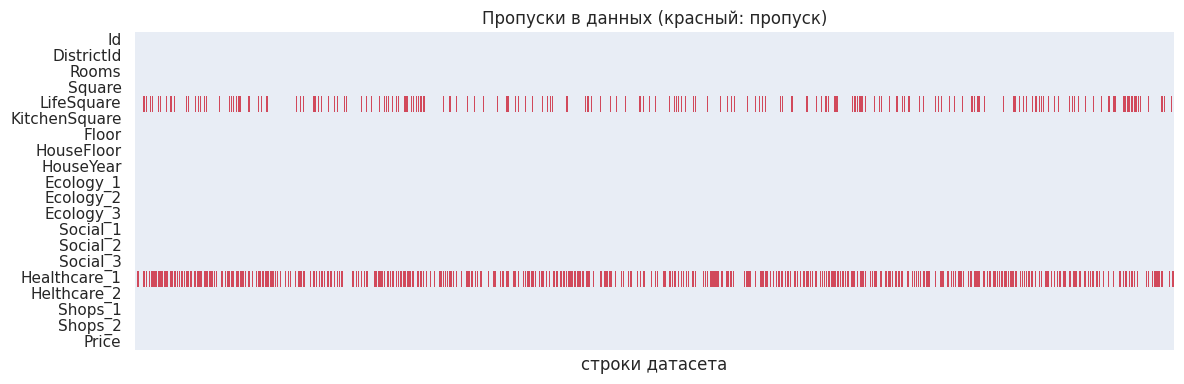

In [6]:
fig, ax = plt.subplots(figsize=(12, 4))
sns.heatmap(df.isna().T, cbar=False, cmap=["#e8edf5", "#d1495b"], ax=ax, yticklabels=True)
ax.set_xticks([])
ax.set_title("Пропуски в данных (красный: пропуск)")
ax.set_xlabel("строки датасета")
plt.tight_layout(); plt.show()

Пропуски есть в двух столбцах:
- `LifeSquare`: 21%. Жилую площадь можно разумно восстановить по общей площади;
- `Healthcare_1`: 48%, почти половина. Это показатель района, поэтому логично заполнять его медианой по району.

### 2.2 Аномалии: статистические методы

**Метод межквартильного размаха (IQR).**
Q1 и Q3 это 25-й и 75-й перцентили, IQR = Q3 − Q1.
Значение считается выбросом, если оно меньше Q1 − 1.5·IQR или больше Q3 + 1.5·IQR.
На этом же правиле построены «усы» BoxPlot.

**Метод Z-оценки.** z = (x − среднее) / стандартное отклонение, выбросом считается |z| > 3.
Метод хорошо работает для нормально распределённых данных, но само среднее сильно сдвигается от выбросов,
поэтому IQR обычно надёжнее.

In [7]:
num_cols = ["Rooms", "Square", "LifeSquare", "KitchenSquare", "Floor", "HouseFloor",
            "HouseYear", "Social_3", "Healthcare_1", "Price"]

def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

rows = []
for col in num_cols:
    s = df[col].dropna()
    lo, hi = iqr_bounds(s)
    z = (s - s.mean()) / s.std()
    rows.append({"признак": col, "нижняя граница IQR": round(lo, 1), "верхняя граница IQR": round(hi, 1),
                 "выбросов по IQR": int(((s < lo) | (s > hi)).sum()),
                 "выбросов по |z|>3": int((z.abs() > 3).sum())})
pd.DataFrame(rows)

,признак,нижняя граница IQR,верхняя граница IQR,выбросов по IQR,выбросов по |z|>3
0,Rooms,-0.5,3.5,172,22
1,Square,5.6,102.1,242,93
2,LifeSquare,-10.8,78.7,240,4
3,KitchenSquare,-11.0,21.0,47,6
4,Floor,-8.0,24.0,66,66
5,HouseFloor,-3.0,29.0,49,23
6,HouseYear,1933.5,2041.5,38,1
7,Social_3,-7.5,12.5,862,340
8,Healthcare_1,-1447.0,3345.0,212,88
9,Price,10978.4,392029.7,583,175


**Важно:** не всё, что IQR считает выбросом, является ошибкой.
У площади и цены распределение скошено вправо: больших квартир меньше, но они настоящие.
Если срезать всё выше Q3 + 1.5·IQR, мы выбросим реальные дорогие квартиры.
Поэтому статистику дополняем **логическими (предметными) проверками**:

In [8]:
checks = {
    "HouseYear > 2020 (год из будущего)":      (df.HouseYear > 2020).sum(),
    "Rooms == 0":                              (df.Rooms == 0).sum(),
    "Rooms > 5":                               (df.Rooms > 5).sum(),
    "Square < 15 м²":                          (df.Square < 15).sum(),
    "LifeSquare > Square":                     (df.LifeSquare > df.Square).sum(),
    "LifeSquare < 10 м²":                      (df.LifeSquare < 10).sum(),
    "KitchenSquare < 3 м² (не указана)":       (df.KitchenSquare < 3).sum(),
    "KitchenSquare > 30 м² или > Square/2":    ((df.KitchenSquare > 30) | (df.KitchenSquare > df.Square / 2)).sum(),
    "HouseFloor == 0":                         (df.HouseFloor == 0).sum(),
    "HouseFloor > 60":                         (df.HouseFloor > 60).sum(),
    "Floor > HouseFloor (этаж выше дома)":     (df.Floor > df.HouseFloor).sum(),
}
pd.Series(checks, name="строк").to_frame()

,строк
HouseYear > 2020 (год из будущего),2
Rooms == 0,8
Rooms > 5,4
Square < 15 м²,13
LifeSquare > Square,482
LifeSquare < 10 м²,205
KitchenSquare < 3 м² (не указана),3161
KitchenSquare > 30 м² или > Square/2,39
HouseFloor == 0,269
HouseFloor > 60,3


### 2.3 Аномалии: графики

**Гистограмма** показывает форму распределения. Длинный «хвост» или одиночный столбик далеко справа указывают на выбросы.

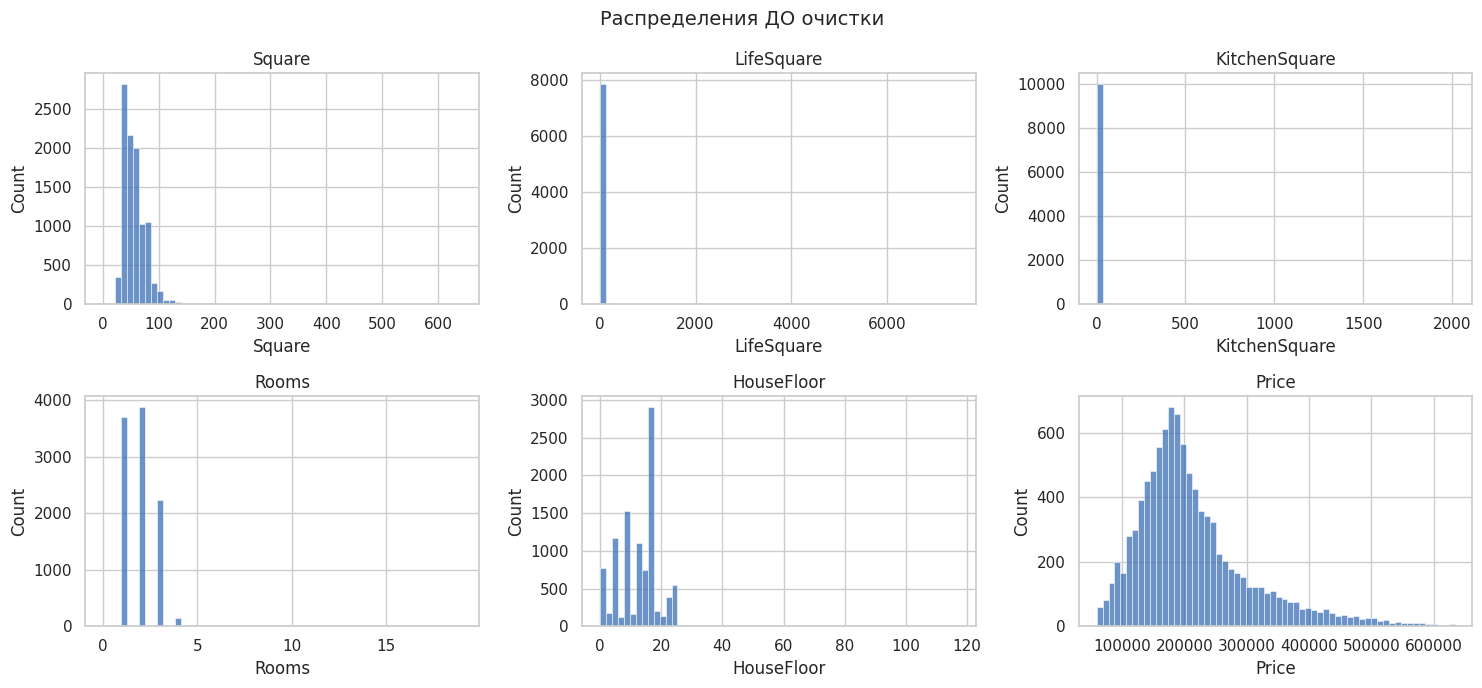

In [9]:
cols = ["Square", "LifeSquare", "KitchenSquare", "Rooms", "HouseFloor", "Price"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.ravel(), cols):
    sns.histplot(df[col].dropna(), bins=60, ax=ax, color=MAIN)
    ax.set_title(col)
plt.suptitle("Распределения ДО очистки", fontsize=14)
plt.tight_layout(); plt.show()

**BoxPlot (ящик с усами).** Ящик занимает промежуток от Q1 до Q3, линия внутри это медиана, усы тянутся до 1.5·IQR.
Точки за усами это кандидаты в выбросы. Видно, что у площадей несколько точек улетают в сотни и тысячи м²,
а у `HouseYear` одна точка сжимает весь график.

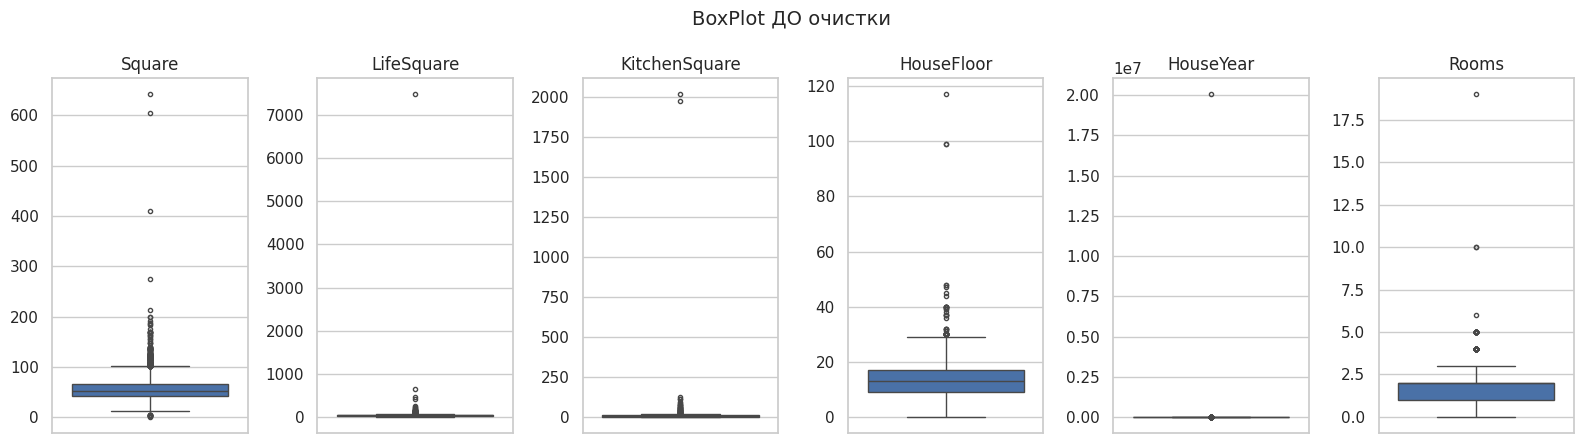

In [10]:
cols = ["Square", "LifeSquare", "KitchenSquare", "HouseFloor", "HouseYear", "Rooms"]
fig, axes = plt.subplots(1, 6, figsize=(16, 4.5))
for ax, col in zip(axes, cols):
    sns.boxplot(y=df[col], ax=ax, color=MAIN, flierprops={"markersize": 3})
    ax.set_title(col); ax.set_ylabel("")
plt.suptitle("BoxPlot ДО очистки", fontsize=14)
plt.tight_layout(); plt.show()

**Диаграмма рассеяния** «общая площадь → жилая площадь». Все нормальные точки должны лежать **ниже** диагонали y = x,
потому что жилая площадь не может превышать общую.

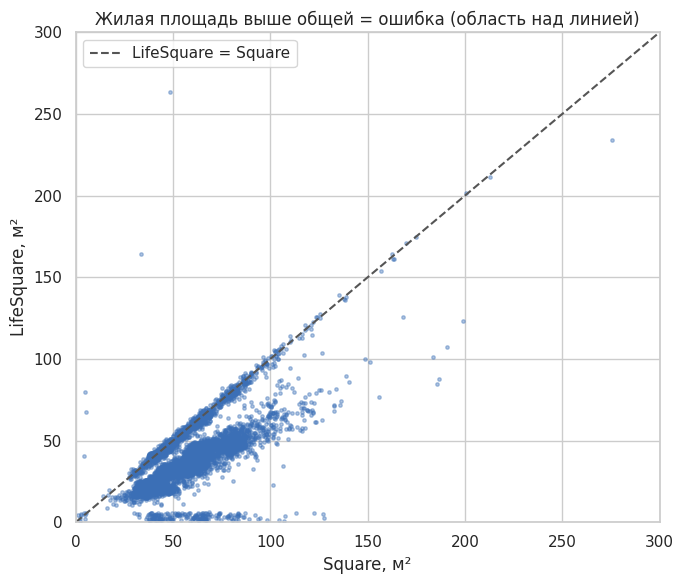

In [11]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(df.Square, df.LifeSquare, s=6, alpha=0.4, color=MAIN)
lim = 300
ax.plot([0, lim], [0, lim], color="#555", lw=1.5, ls="--", label="LifeSquare = Square")
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_xlabel("Square, м²"); ax.set_ylabel("LifeSquare, м²")
ax.set_title("Жилая площадь выше общей = ошибка (область над линией)")
ax.legend(); plt.tight_layout(); plt.show()

### 2.4 Заполнение пропусков и устранение выбросов

Принцип: **ошибочное значение превращаем в пропуск, а затем заполняем пропуск разумным значением.**
Выбрасывать строки жалко, потому что в них остальные признаки нормальные.
Для заполнения берём **медиану**: в отличие от среднего, она не сдвигается от выбросов.

Порядок важен. Сначала чиним «опорные» признаки (год, общая площадь, комнаты), потом зависящие от них (жилая площадь, кухня, этажи).

**1) HouseYear.** Год больше 2020 (данные собраны в 2020 году) это опечатка.
`20052011` превращаем в 2005, `4968` в 1968 (первая цифра набрана неверно).
Всё, что после этого осталось некорректным, заменяем медианой.

In [12]:
df.loc[df.HouseYear == 20052011, "HouseYear"] = 2005
df.loc[df.HouseYear == 4968, "HouseYear"] = 1968
df.loc[df.HouseYear > 2020, "HouseYear"] = df.HouseYear.median()
df.HouseYear.describe()[["min", "max"]]

min    1910.0
max    2020.0
Name: HouseYear, dtype: float64

**2) Square.** Квартира меньше 15 м² в этом датасете почти наверняка ошибка ввода.
Заменяем такие значения медианой площади для квартир с тем же числом комнат.
`groupby("Rooms").transform("median")` для каждой строки возвращает медиану её группы.

In [13]:
df.loc[df.Square < 15, "Square"] = np.nan
df["Square"] = df.Square.fillna(df.groupby("Rooms").Square.transform("median"))
df["Square"] = df.Square.fillna(df.Square.median())   # на случай, если вся группа была пустой

**3) Rooms.** 0 комнат или больше 5 при обычной площади это ошибка.
Оцениваем число комнат по площади: делим площадь на типичную площадь одной комнаты и ограничиваем результат от 1 до 5.

In [14]:
ok = df.Rooms.between(1, 5)
m2_per_room = (df.loc[ok, "Square"] / df.loc[ok, "Rooms"]).median()
print(f"Типичная площадь на одну комнату: {m2_per_room:.1f} м²")
bad = ~ok
df.loc[bad, "Rooms"] = (df.loc[bad, "Square"] / m2_per_room).round().clip(1, 5)
df.Rooms.value_counts().sort_index()

Типичная площадь на одну комнату: 30.8 м²


Rooms
1.0    3708
2.0    3884
3.0    2238
4.0     151
5.0      19
Name: count, dtype: int64

**4) KitchenSquare.** Значения меньше 3 м² (часто 0 или 1) означают, что кухня не указана.
Больше 30 м² или больше половины квартиры это ошибка. Такие значения заменяем медианой кухни по числу комнат.

In [15]:
bad_k = (df.KitchenSquare < 3) | (df.KitchenSquare > 30) | (df.KitchenSquare > df.Square / 2)
df.loc[bad_k, "KitchenSquare"] = np.nan
df["KitchenSquare"] = df.KitchenSquare.fillna(df.groupby("Rooms").KitchenSquare.transform("median"))
print("Исправлено кухонь:", bad_k.sum())

Исправлено кухонь: 3197


**5) LifeSquare.** Сначала помечаем ошибки как пропуски: жилая площадь больше общей, меньше 10 м²
или вместе с кухней больше общей площади. Потом заполняем все пропуски (исходные и новые)
через типичную **долю** жилой площади от общей: `LifeSquare = Square × медианная доля`.
Это точнее, чем одна общая медиана, потому что у большой квартиры и жилая площадь большая.

In [16]:
bad_l = (df.LifeSquare > df.Square) | (df.LifeSquare < 10) | (df.LifeSquare + df.KitchenSquare > df.Square)
df.loc[bad_l, "LifeSquare"] = np.nan
share = (df.LifeSquare / df.Square).median()
print(f"Медианная доля жилой площади: {share:.2f}")
df["LifeSquare"] = df.LifeSquare.fillna(df.Square * share)

Медианная доля жилой площади: 0.60


**6) HouseFloor и Floor.** Дом с 0 этажей и дома выше 60 этажей (в данных есть 117) считаем ошибкой
и заменяем медианой. Если этаж квартиры оказался выше этажности дома, берём этажность равной этажу квартиры,
потому что сам этаж квартиры указан надёжнее.

In [17]:
df.loc[(df.HouseFloor == 0) | (df.HouseFloor > 60), "HouseFloor"] = np.nan
df["HouseFloor"] = df.HouseFloor.fillna(df.HouseFloor.median())
df["HouseFloor"] = np.maximum(df.HouseFloor, df.Floor)
print("Этаж выше дома:", (df.Floor > df.HouseFloor).sum())

Этаж выше дома: 0


**7) Healthcare_1.** Пропущено 48%. Показатель относится к району, поэтому заполняем медианой **по району**
(`DistrictId`). Если в районе вообще нет значений, берём общую медиану.
Факт пропуска сам по себе может быть информативен, поэтому перед заполнением сохраним его
в отдельный признак-флаг (он пригодится в п. 3).

In [18]:
df["Healthcare_1_missing"] = df.Healthcare_1.isna().astype(int)
df["Healthcare_1"] = df.Healthcare_1.fillna(df.groupby("DistrictId").Healthcare_1.transform("median"))
df["Healthcare_1"] = df.Healthcare_1.fillna(df.Healthcare_1.median())

**8) Ограничение хвостов (винзоризация).** После исправления явных ошибок у площадей ещё остаются
редкие экстремальные значения. Мы не удаляем их, а «прижимаем» к 0.5-му и 99.5-му перцентилям методом `clip`.
Порог выбран мягче IQR, чтобы не потерять настоящие большие квартиры.

Целевую переменную `Price` **не трогаем**: дорогие квартиры реальны, и модель должна учиться и на них.

In [19]:
for col in ["Square", "LifeSquare", "KitchenSquare"]:
    lo, hi = df[col].quantile([0.005, 0.995])
    df[col] = df[col].clip(lo, hi)
    print(f"{col}: оставлен диапазон [{lo:.1f}; {hi:.1f}]")

Square: оставлен диапазон [28.1; 132.8]
LifeSquare: оставлен диапазон [15.1; 81.6]
KitchenSquare: оставлен диапазон [4.0; 17.0]


### 2.5 Проверка: пропусков и аномалий не осталось

In [20]:
print("Всего пропусков:", df.isna().sum().sum())
pd.Series({k: v for k, v in {
    "HouseYear > 2020": (df.HouseYear > 2020).sum(),
    "Rooms вне 1..5": (~df.Rooms.between(1, 5)).sum(),
    "Square < 15": (df.Square < 15).sum(),
    "LifeSquare > Square": (df.LifeSquare > df.Square).sum(),
    "KitchenSquare < 3": (df.KitchenSquare < 3).sum(),
    "HouseFloor == 0": (df.HouseFloor == 0).sum(),
    "Floor > HouseFloor": (df.Floor > df.HouseFloor).sum(),
}.items()}, name="строк").to_frame()

Всего пропусков: 0


,строк
HouseYear > 2020,0
Rooms вне 1..5,0
Square < 15,0
LifeSquare > Square,0
KitchenSquare < 3,0
HouseFloor == 0,0
Floor > HouseFloor,0


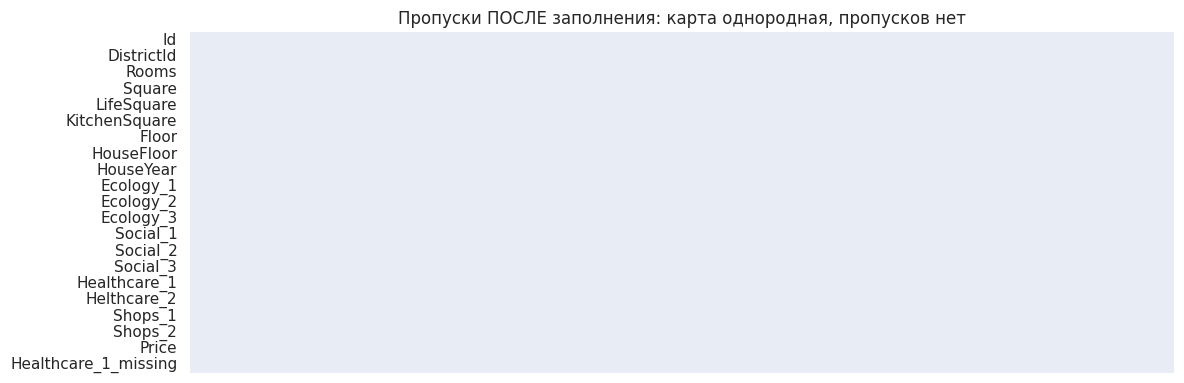

In [21]:
fig, ax = plt.subplots(figsize=(12, 4))
sns.heatmap(df.isna().T, cbar=False, cmap=["#e8edf5", "#d1495b"], ax=ax, yticklabels=True, vmin=0, vmax=1)
ax.set_xticks([])
ax.set_title("Пропуски ПОСЛЕ заполнения: карта однородная, пропусков нет")
plt.tight_layout(); plt.show()

**BoxPlot до и после.** Слева исходные данные, справа очищенные. У каждого признака своя шкала:
признаки сравниваются каждый сам с собой, а не друг с другом.

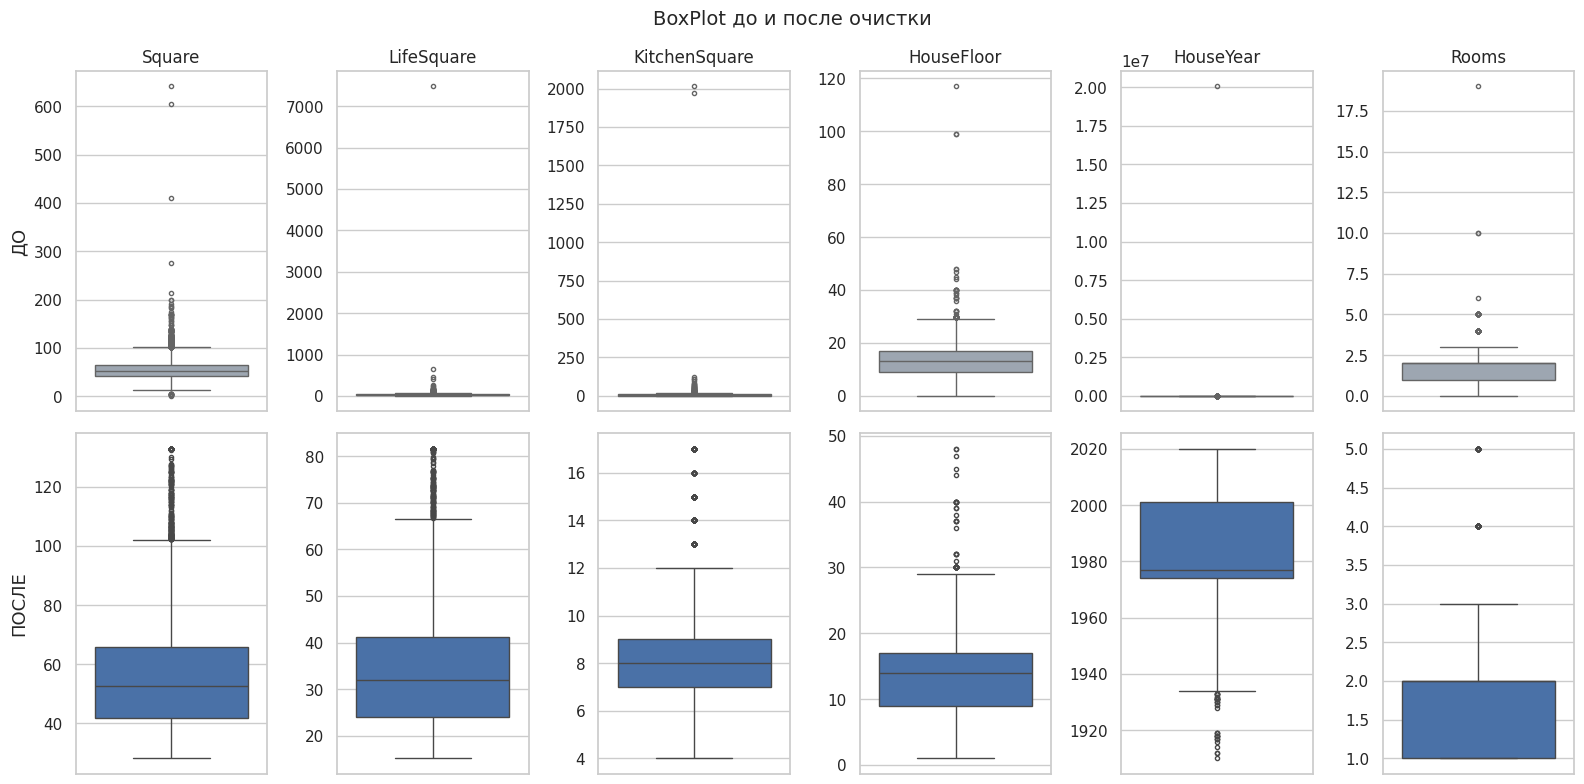

In [22]:
cols = ["Square", "LifeSquare", "KitchenSquare", "HouseFloor", "HouseYear", "Rooms"]
fig, axes = plt.subplots(2, 6, figsize=(16, 8))
for i, col in enumerate(cols):
    sns.boxplot(y=raw[col], ax=axes[0, i], color="#9aa5b4", flierprops={"markersize": 3})
    sns.boxplot(y=df[col], ax=axes[1, i], color=MAIN, flierprops={"markersize": 3})
    axes[0, i].set_title(col); axes[0, i].set_ylabel(""); axes[1, i].set_ylabel("")
axes[0, 0].set_ylabel("ДО", fontsize=13); axes[1, 0].set_ylabel("ПОСЛЕ", fontsize=13)
plt.suptitle("BoxPlot до и после очистки", fontsize=14)
plt.tight_layout(); plt.show()

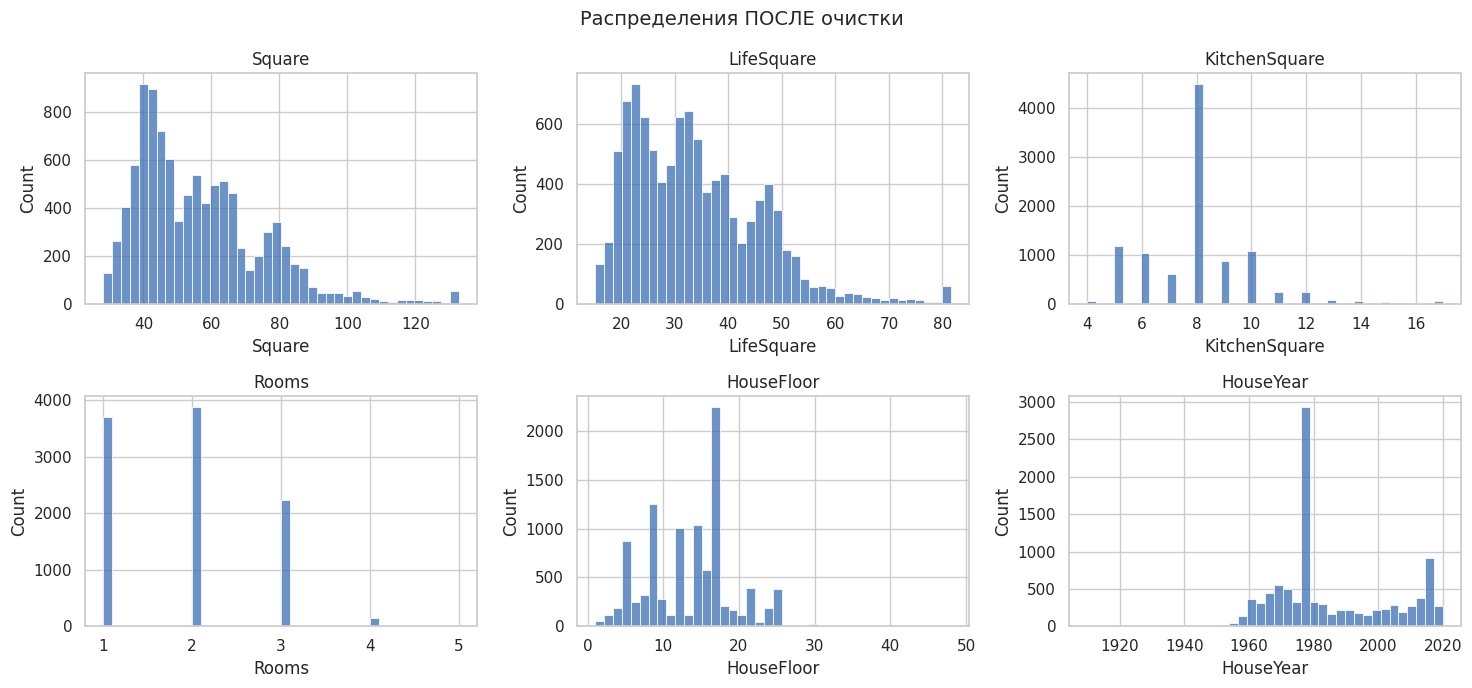

In [23]:
cols = ["Square", "LifeSquare", "KitchenSquare", "Rooms", "HouseFloor", "HouseYear"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.ravel(), cols):
    sns.histplot(df[col], bins=40, ax=ax, color=MAIN)
    ax.set_title(col)
plt.suptitle("Распределения ПОСЛЕ очистки", fontsize=14)
plt.tight_layout(); plt.show()

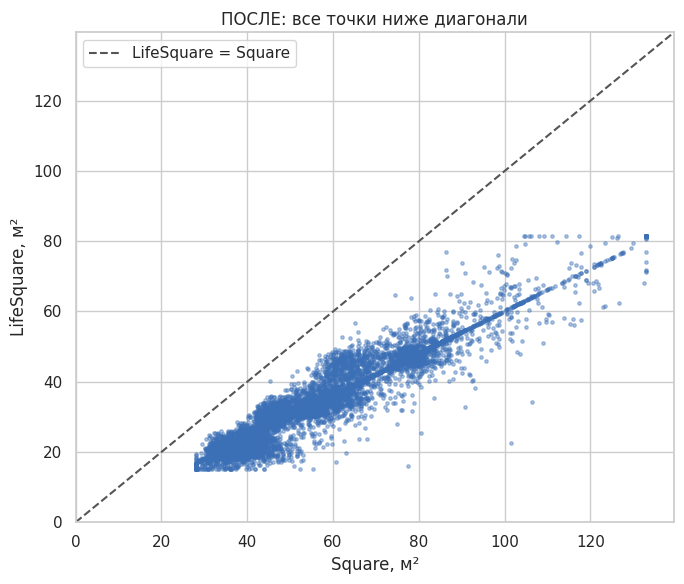

In [24]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(df.Square, df.LifeSquare, s=6, alpha=0.4, color=MAIN)
lim = df.Square.max() * 1.05
ax.plot([0, lim], [0, lim], color="#555", lw=1.5, ls="--", label="LifeSquare = Square")
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_xlabel("Square, м²"); ax.set_ylabel("LifeSquare, м²")
ax.set_title("ПОСЛЕ: все точки ниже диагонали"); ax.legend()
plt.tight_layout(); plt.show()

**Как читать графики «после».** Точки за усами на нижнем ряду остались, и это нормально.
BoxPlot по правилу 1.5·IQR помечает любые редкие значения, но теперь это реальные квартиры:
площадь 100–130 м², 4–5 комнат, дома 1910-х годов и высотки до 48 этажей.
Главное, что исчезли **невозможные** значения, из-за которых на верхнем ряду весь ящик сжимался в полоску.

### 2.6 Корреляции

Тепловая карта корреляций показывает, какие признаки связаны между собой и с ценой.
Коэффициент корреляции Пирсона лежит в диапазоне от −1 до 1: около 0 связи нет, ближе к ±1 связь сильная линейная.

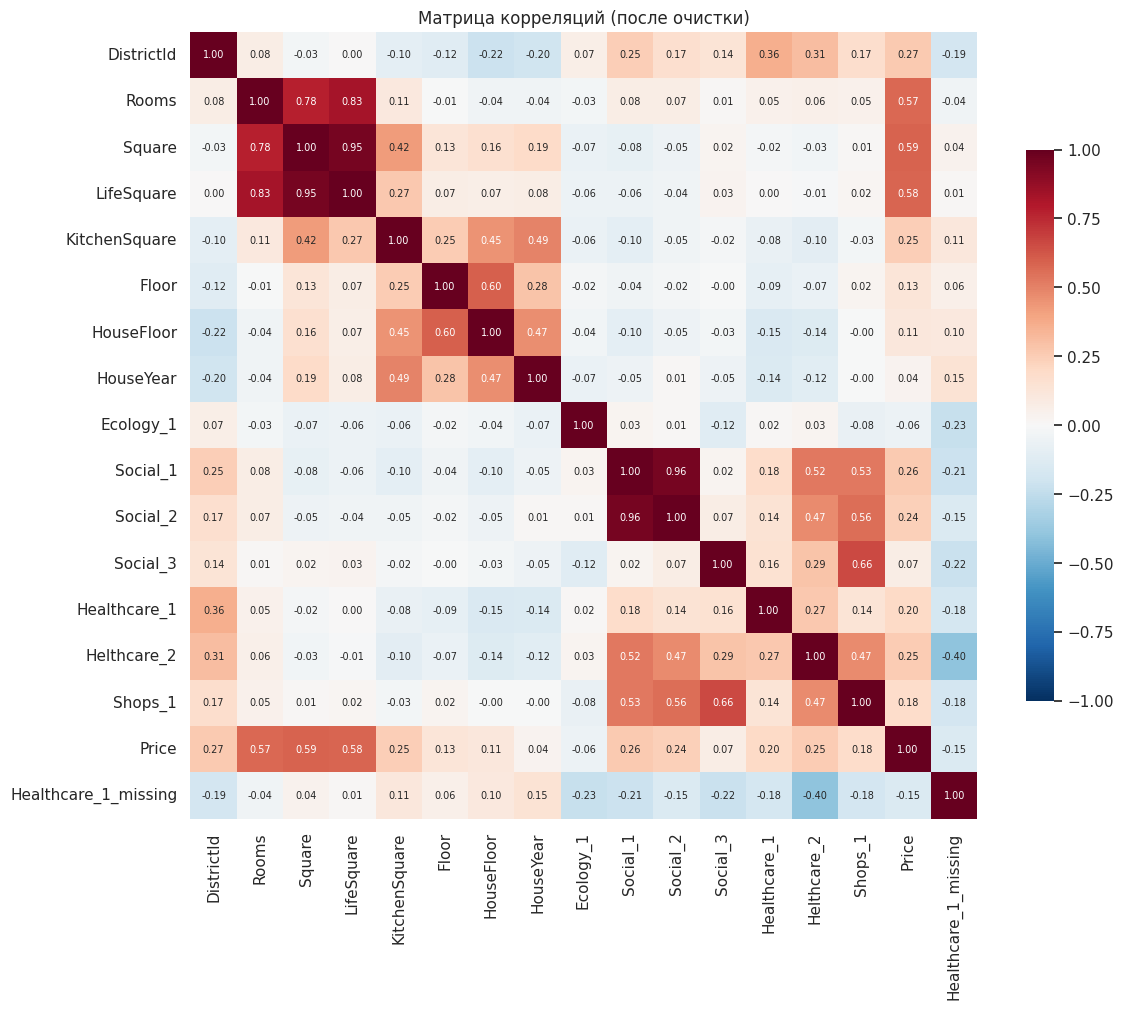

Square                  0.59
LifeSquare              0.58
Rooms                   0.57
DistrictId              0.27
Social_1                0.26
Helthcare_2             0.25
KitchenSquare           0.25
Social_2                0.24
Healthcare_1            0.20
Shops_1                 0.18
Floor                   0.13
HouseFloor              0.11
Social_3                0.07
HouseYear               0.04
Ecology_1              -0.06
Healthcare_1_missing   -0.15
Name: Price, dtype: float64

In [25]:
corr = df.drop(columns=["Id"]).select_dtypes("number").corr()
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 7}, square=True, ax=ax, cbar_kws={"shrink": 0.7})
ax.set_title("Матрица корреляций (после очистки)")
plt.tight_layout(); plt.show()
corr["Price"].drop("Price").sort_values(ascending=False).round(2)

Сильнее всего с ценой связаны площади и число комнат, что логично.
`Social_1`, `Social_2` и `Social_3` сильно коррелируют друг с другом: они описывают одно и то же свойство района.

## 3. Новые признаки и кодирование категориальных

### 3.1 Генерация новых признаков (feature engineering)
Новые признаки дают модели информацию «в готовом виде», которую ей трудно извлечь самой:

| Новый признак | Формула | Зачем |
|---|---|---|
| `HouseAge` | 2020 − HouseYear | возраст дома понятнее года постройки |
| `SquarePerRoom` | Square / Rooms | просторность квартиры |
| `KitchenShare` | KitchenSquare / Square | доля кухни, признак планировки |
| `RelativeFloor` | Floor / HouseFloor | положение по высоте: 0 внизу, 1 наверху |
| `FloorCategory` | первый / последний / средний | первый и последний этажи традиционно дешевле |
| `DistrictSize` | число квартир в районе | насколько район популярен (частотное кодирование `DistrictId`) |
| `Healthcare_1_missing` | 1, если значение было пропущено | создан в п. 2.4 |

In [26]:
df["HouseAge"] = 2020 - df.HouseYear
df["SquarePerRoom"] = df.Square / df.Rooms
df["KitchenShare"] = df.KitchenSquare / df.Square
df["RelativeFloor"] = df.Floor / df.HouseFloor

df["FloorCategory"] = np.select(
    [df.Floor == 1, df.Floor == df.HouseFloor],
    ["first", "last"],
    default="middle",
)

df["DistrictSize"] = df.groupby("DistrictId").Id.transform("count")

df[["HouseAge", "SquarePerRoom", "KitchenShare", "RelativeFloor", "FloorCategory", "DistrictSize"]].head()

,HouseAge,SquarePerRoom,KitchenShare,RelativeFloor,FloorCategory,DistrictSize
0,6,38.342437,0.086936,0.400000,middle,851
1,54,39.832524,0.200841,0.875000,middle,78
2,32,26.114072,0.127645,0.117647,middle,652
3,43,40.409907,0.197971,0.454545,middle,652
4,48,32.142534,0.140001,1.000000,last,89


Проверим, что новые признаки действительно связаны с ценой.

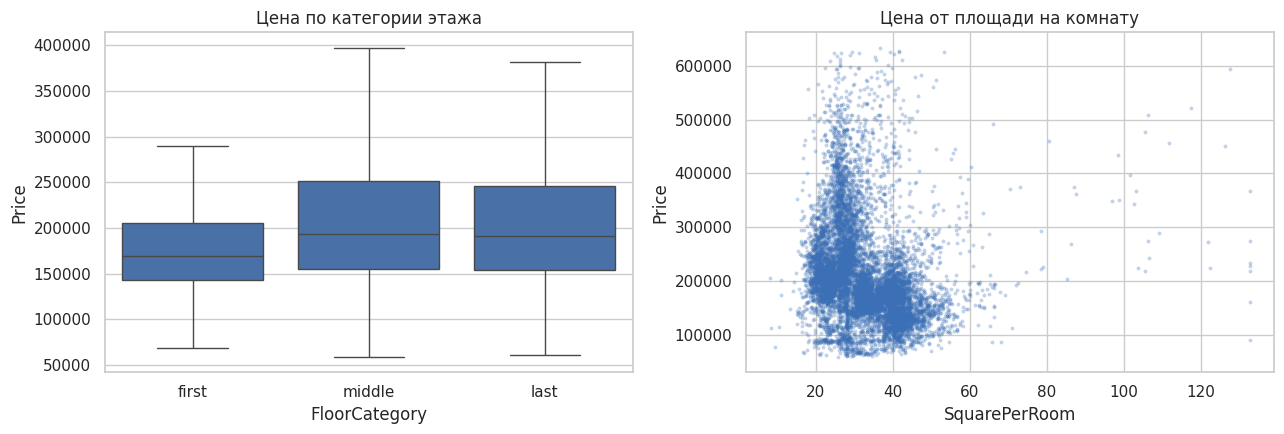

FloorCategory
first     169062.0
middle    193508.0
last      190924.0
Name: Price, dtype: float64

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
order = ["first", "middle", "last"]
sns.boxplot(data=df, x="FloorCategory", y="Price", order=order, ax=axes[0], color=MAIN, showfliers=False)
axes[0].set_title("Цена по категории этажа")
sns.scatterplot(data=df, x="SquarePerRoom", y="Price", s=6, alpha=0.3, ax=axes[1], color=MAIN, edgecolor=None)
axes[1].set_title("Цена от площади на комнату")
plt.tight_layout(); plt.show()
df.groupby("FloorCategory").Price.median().round(0).reindex(order)

### 3.2 Кодирование категориальных признаков

Модели машинного обучения работают с числами, поэтому текстовые категории нужно перевести в числа.

**Бинаризация.** У признака две категории, и они превращаются в 0 и 1.
`Ecology_2`, `Ecology_3` и `Shops_2` принимают значения только A и B, поэтому кодируем `B → 1`, `A → 0`.

In [28]:
for col in ["Ecology_2", "Ecology_3", "Shops_2"]:
    print(col, df[col].value_counts().to_dict())
    df[col] = df[col].map({"A": 0, "B": 1})
df[["Ecology_2", "Ecology_3", "Shops_2"]].head()

Ecology_2 {'B': 9903, 'A': 97}
Ecology_3 {'B': 9725, 'A': 275}
Shops_2 {'B': 9175, 'A': 825}


,Ecology_2,Ecology_3,Shops_2
0,1,1,1
1,1,1,1
2,1,1,1
3,1,1,1
4,1,1,1


**Бинаризация числового признака по порогу** (`Binarizer` из sklearn): значения выше порога становятся 1, остальные 0.
Сделаем признак `IsNew`: 1, если дом построен после 2000 года (современный фонд), иначе 0.

In [29]:
binarizer = Binarizer(threshold=2000)          # HouseYear > 2000 -> 1, иначе 0
df["IsNew"] = binarizer.fit_transform(df[["HouseYear"]]).astype(int).ravel()
df.IsNew.value_counts()

IsNew
0    7465
1    2535
Name: count, dtype: int64

**One-Hot Encoding (OHE).** Признак с k категориями превращается в k столбцов из 0 и 1, где в каждой строке ровно одна единица.
Просто пронумеровать категории нельзя: first = 0, middle = 1, last = 2 навязало бы модели ложный порядок,
как будто last «больше» first.

OHE применяем к `FloorCategory`. Показаны два способа: `pd.get_dummies` (pandas) и `OneHotEncoder` (sklearn).

In [30]:
# Способ 1: pandas
dummies = pd.get_dummies(df.FloorCategory, prefix="Floor", dtype=int)
print(dummies.head())

# Способ 2: sklearn. Энкодер запоминает категории на обучающих данных
# и потом так же кодирует новые (тестовые) данные.
ohe = OneHotEncoder(sparse_output=False, dtype=int)
encoded = ohe.fit_transform(df[["FloorCategory"]])
print("Категории, найденные энкодером:", ohe.categories_[0])

df = pd.concat([df.drop(columns="FloorCategory"), dummies], axis=1)
df.filter(like="Floor").head()

   Floor_first  Floor_last  Floor_middle
0            0           0             1
1            0           0             1
2            0           0             1
3            0           0             1
4            0           1             0
Категории, найденные энкодером: ['first' 'last' 'middle']


,Floor,HouseFloor,RelativeFloor,Floor_first,Floor_last,Floor_middle
0,4,10.0,0.400000,0,0,1
1,7,8.0,0.875000,0,0,1
2,2,17.0,0.117647,0,0,1
3,10,22.0,0.454545,0,0,1
4,16,16.0,1.000000,0,1,0


`DistrictId` тоже категориальный признак, хоть и записан числами: номер района ничего не говорит о его «величине».
Но районов 205, и OHE дал бы 205 новых столбцов. Для такого признака удобнее **частотное кодирование**,
его мы уже сделали в виде `DistrictSize`.

## 4. Стандартизация и нормализация

Признаки измеряются в разных масштабах: `Social_2` порядка тысяч, `KitchenShare` меньше 1.
Многие алгоритмы (kNN, SVM, линейные модели с регуляризацией, нейросети) считают расстояния или градиенты,
и признак с большими числами начинает доминировать просто из-за своего масштаба.

| Метод | Формула | Результат | Когда применять |
|---|---|---|---|
| **Стандартизация** (`StandardScaler`) | z = (x − mean) / std | среднее 0, стандартное отклонение 1 | по умолчанию; линейные модели, SVM, PCA |
| **Нормализация** (`MinMaxScaler`) | x' = (x − min) / (max − min) | все значения в [0; 1] | нужен фиксированный диапазон: нейросети, kNN, изображения |

Что **не** масштабируем:
- `Id`, потому что это не признак;
- `Price`, потому что это целевая переменная;
- бинарные признаки 0/1 (они уже в нужном масштабе).

In [31]:
binary_cols = [c for c in df.columns if set(df[c].unique()) <= {0, 1}]
feature_cols = [c for c in df.columns if c not in ["Id", "Price", "DistrictId"] + binary_cols]
print("Бинарные (не масштабируем):", binary_cols)
print("Масштабируем:", feature_cols)

Бинарные (не масштабируем): ['Ecology_2', 'Ecology_3', 'Shops_2', 'Healthcare_1_missing', 'IsNew', 'Floor_first', 'Floor_last', 'Floor_middle']
Масштабируем: ['Rooms', 'Square', 'LifeSquare', 'KitchenSquare', 'Floor', 'HouseFloor', 'HouseYear', 'Ecology_1', 'Social_1', 'Social_2', 'Social_3', 'Healthcare_1', 'Helthcare_2', 'Shops_1', 'HouseAge', 'SquarePerRoom', 'KitchenShare', 'RelativeFloor', 'DistrictSize']


In [32]:
std_scaler = StandardScaler()
df_std = df.copy()
df_std[feature_cols] = std_scaler.fit_transform(df[feature_cols])

mm_scaler = MinMaxScaler()
df_mm = df.copy()
df_mm[feature_cols] = mm_scaler.fit_transform(df[feature_cols])

show = ["Square", "Social_2", "HouseAge", "KitchenShare"]
pd.concat({
    "исходные": df[show].agg(["mean", "std", "min", "max"]),
    "StandardScaler": df_std[show].agg(["mean", "std", "min", "max"]),
    "MinMaxScaler": df_mm[show].agg(["mean", "std", "min", "max"]),
}).round(3)

Square   Social_2  HouseAge  KitchenShare
исходные       mean   56.155   5352.157    35.134         0.152
               std    18.431   4006.800    18.412         0.046
               min    28.145    168.000     0.000         0.036
               max   132.821  19083.000   110.000         0.423
StandardScaler mean    0.000     -0.000    -0.000         0.000
               std     1.000      1.000     1.000         1.000
               min    -1.520     -1.294    -1.908        -2.503
               max     4.160      3.427     4.066         5.896
MinMaxScaler   mean    0.268      0.274     0.319         0.298
               std     0.176      0.212     0.167         0.119
               min     0.000      0.000     0.000         0.000
               max     1.000      1.000     1.000         1.000

После `StandardScaler` у каждого признака среднее 0 и стандартное отклонение 1.
После `MinMaxScaler` минимум равен 0, а максимум 1.
Масштабирование **не меняет форму распределения**, меняется только шкала по оси X. Это хорошо видно на графике:

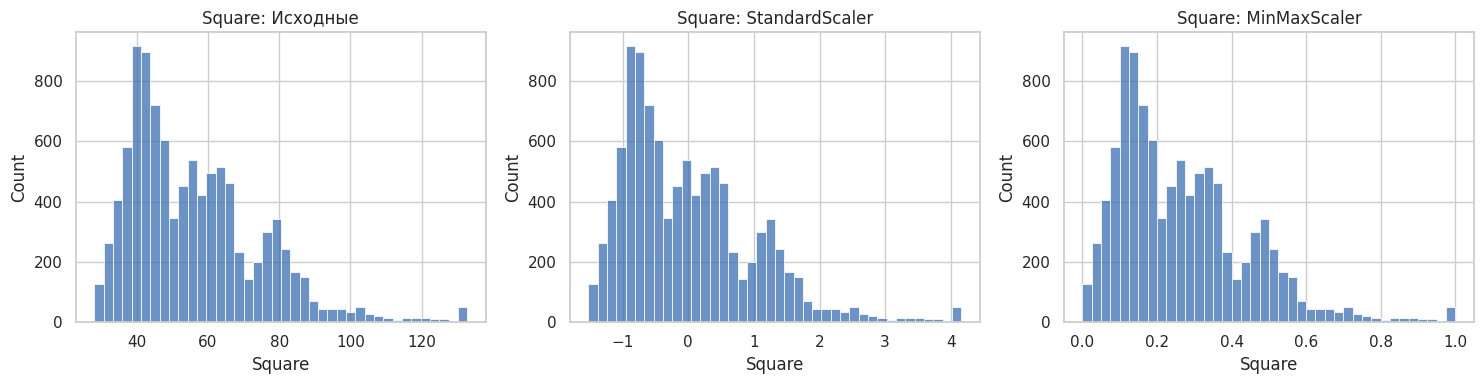

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, data, title in zip(axes, [df, df_std, df_mm], ["Исходные", "StandardScaler", "MinMaxScaler"]):
    sns.histplot(data["Square"], bins=40, ax=ax, color=MAIN)
    ax.set_title(f"Square: {title}")
plt.tight_layout(); plt.show()

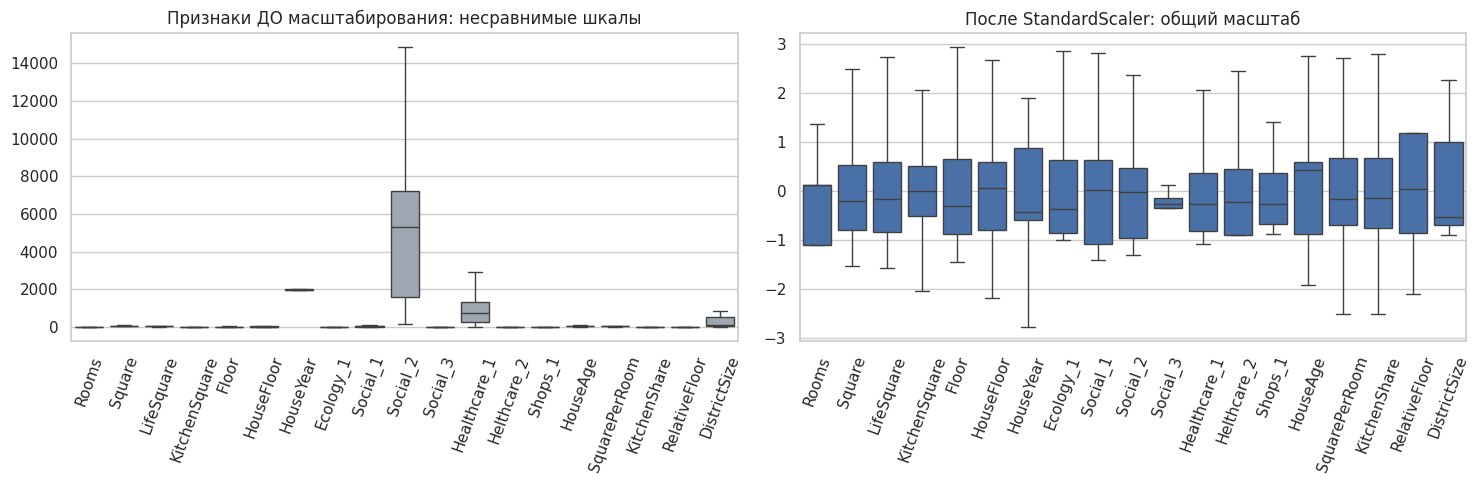

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=df[feature_cols], ax=axes[0], color="#9aa5b4", showfliers=False)
axes[0].set_title("Признаки ДО масштабирования: несравнимые шкалы")
axes[0].tick_params(axis="x", rotation=70)
sns.boxplot(data=df_std[feature_cols], ax=axes[1], color=MAIN, showfliers=False)
axes[1].set_title("После StandardScaler: общий масштаб")
axes[1].tick_params(axis="x", rotation=70)
plt.tight_layout(); plt.show()

> **Важно для будущих работ с моделями.** Scaler «учится» (`fit`) только на обучающей выборке,
> а к тестовой применяется `transform` с уже найденными mean/std. Иначе в модель «утечёт»
> информация из теста (data leakage). Здесь мы только готовим данные, поэтому `fit` делаем на всём датасете.

Сохраним подготовленные данные:

In [35]:
df.to_csv("real_estate_clean.csv", index=False)
df_std.to_csv("real_estate_standardized.csv", index=False)
print("Итоговый размер:", df.shape)
df_std.head()

Итоговый размер: (10000, 30)


,Id,DistrictId,Rooms,Square,LifeSquare,KitchenSquare,Floor,HouseFloor,HouseYear,Ecology_1,Ecology_2,Ecology_3,Social_1,Social_2,Social_3,Healthcare_1,Helthcare_2,Shops_1,Shops_2,Price,Healthcare_1_missing,HouseAge,SquarePerRoom,KitchenShare,RelativeFloor,DistrictSize,IsNew,Floor_first,Floor_last,Floor_middle
0,11809,27,1.367922,3.194435,2.964552,1.037842,-0.863728,-0.616142,1.582475,-0.364931,1,1,-0.780698,-0.562861,-0.337347,-0.254088,-0.883480,-0.880402,1,305018.871089,1,-1.582475,0.603091,-1.405562,-0.879579,2.262976,1,0,0,1
1,3013,22,-1.094362,-0.885670,-0.896433,0.012129,-0.291306,-0.962114,-1.024720,-0.002690,1,1,0.303050,0.213359,-0.295384,0.215471,-0.213923,-0.880402,1,177734.553407,0,1.024720,0.755500,1.072202,0.764843,-0.610852,0,0,0,1
2,8215,1,1.367922,1.203884,1.155696,1.037842,-1.245343,0.594761,0.170244,-0.783473,1,1,0.474169,-0.022752,-0.337347,-0.807148,1.125190,-0.672333,1,282078.720850,0,-0.170244,-0.647649,-0.520018,-1.857069,1.523142,0,0,0,1
3,2352,1,-1.094362,-0.854341,-0.798795,0.012129,0.281117,1.459691,-0.427238,-0.938799,1,1,-1.351093,-1.269944,-0.337347,-0.807148,-0.883480,-0.672333,1,168106.007630,1,0.427238,0.814556,1.009779,-0.690746,1.523142,0,0,0,1
4,13866,94,0.136780,0.441137,0.392770,0.524986,1.425961,0.421775,-0.698820,1.377425,1,1,0.474169,0.827346,-0.253421,-0.254088,-0.883480,0.368011,1,343995.102962,1,0.698820,-0.031046,-0.251233,1.197586,-0.569957,0,0,1,0


## Выводы

1. Датасет из 10 000 квартир импортирован из zip-архива функцией `pd.read_csv`.
2. **Пропуски** найдены в `LifeSquare` (21%) и `Healthcare_1` (48%). Жилая площадь восстановлена через медианную долю
   от общей, `Healthcare_1` заполнен медианой по району, а факт пропуска сохранён отдельным признаком.
3. **Аномалии** найдены методами IQR и Z-оценки, на гистограммах, BoxPlot и диаграммах рассеяния, а также логическими проверками:
   год 20 052 011, 0 и 19 комнат, площадь 1 м², кухня 2 014 м², жилая площадь больше общей, дом с 0 этажей.
   Ошибочные значения заменены медианами по группам, хвосты площадей ограничены перцентилями.
   Графики «после» и повторные проверки подтверждают, что пропусков и аномалий не осталось.
4. **Сгенерированы признаки** `HouseAge`, `SquarePerRoom`, `KitchenShare`, `RelativeFloor`, `FloorCategory`, `DistrictSize`,
   `Healthcare_1_missing`, `IsNew`.
   **Кодирование:** бинаризация A/B → 0/1 (`Ecology_2`, `Ecology_3`, `Shops_2`), пороговая бинаризация `Binarizer` (`IsNew`),
   One-Hot Encoding (`FloorCategory`), частотное кодирование (`DistrictId` → `DistrictSize`).
5. Выполнены **стандартизация** (`StandardScaler`: mean = 0, std = 1) и **нормализация** (`MinMaxScaler`: диапазон [0; 1]).
   Данные готовы к обучению моделей.